# HDI Classification: Exploratory Data Analysis

Here we look at our country dataset before building any models. It is made by `src/build_dataset.py` and the columns
are explained in `data/DATA_DICTIONARY.md`. Nothing is fitted here, the preprocessing is done in `02_modeling.ipynb`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# save the plots here, we need them for the report
FIG_DIR = '../outputs/figures'
os.makedirs(FIG_DIR, exist_ok=True)

sns.set_theme(style='whitegrid')
pd.set_option('display.precision', 2)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

df = pd.read_csv('../data/hdi_dataset_2023.csv')
df.head()

,iso3,country,hdi,hdi_class,region,gdp_growth,inflation,unemployment,infant_mortality,electricity_access,...,services_share_est,gdp_growth_year,inflation_year,unemployment_year,infant_mortality_year,electricity_access_year,internet_users_year,agriculture_share_year,industry_share_year,trade_year
0,AFG,Afghanistan,0.50,0,"Middle East, North Africa, Afghanistan & Pakistan",2.27,-4.64,14.01,49.9,85.3,...,51.81,2023.0,2023.0,2023.0,2023.0,2023,2023.0,2023.0,2023.0,2023.0
1,AGO,Angola,0.62,1,Sub-Saharan Africa,1.32,13.64,14.05,33.0,51.1,...,43.39,2023.0,2023.0,2023.0,2023.0,2023,2023.0,2023.0,2023.0,2023.0
2,ALB,Albania,0.81,2,Europe & Central Asia,4.02,4.76,10.67,8.3,100.0,...,60.57,2023.0,2023.0,2023.0,2023.0,2023,2023.0,2023.0,2023.0,2023.0
3,AND,Andorra,0.91,2,Europe & Central Asia,2.58,NaN,NaN,2.5,100.0,...,87.09,2023.0,NaN,NaN,2023.0,2023,2023.0,2023.0,2023.0,NaN
4,ARE,United Arab Emirates,0.94,2,"Middle East, North Africa, Afghanistan & Pakistan",4.30,1.63,2.15,4.0,100.0,...,53.84,2023.0,2023.0,2023.0,2023.0,2023,2023.0,2023.0,2023.0,2023.0


In [2]:
num_cols = ['gdp_growth', 'inflation', 'unemployment', 'infant_mortality', 'electricity_access',
            'internet_users', 'agriculture_share', 'industry_share', 'trade']
cat_cols = ['region', 'DominantSector']

class_names = {0: 'Low', 1: 'Medium/High', 2: 'Very High'}
class_order = ['Low', 'Medium/High', 'Very High']
class_colors = {'Low': '#d95f02', 'Medium/High': '#7570b3', 'Very High': '#1b9e77'}

# class names instead of 0/1/2, just for the plots and tables
df['hdi_label'] = df['hdi_class'].map(class_names)

## 1. Overview of the dataset

In [3]:
print('Number of countries:', len(df))
print('Numerical features:', len(num_cols))
print('Categorical features:', len(cat_cols))
print()
print(df[num_cols + cat_cols].dtypes)

Number of countries: 193
Numerical features: 9
Categorical features: 2

gdp_growth            float64
inflation             float64
unemployment          float64
infant_mortality      float64
electricity_access    float64
internet_users        float64
agriculture_share     float64
industry_share        float64
trade                 float64
region                 object
DominantSector         object
dtype: object


In [4]:
# describe() plus skew and number of missing values
summary = df[num_cols].describe().T
summary['skew'] = df[num_cols].skew()
summary['missing'] = df[num_cols].isnull().sum()
summary

,count,mean,std,min,25%,50%,75%,max,skew,missing
gdp_growth,189.0,2.94,4.62,-29.43,1.13,3.13,4.94,33.80,-0.68,4
inflation,178.0,11.48,23.84,-4.64,3.61,5.87,9.33,221.34,5.98,15
unemployment,179.0,6.89,5.71,0.13,3.15,5.18,8.50,34.61,2.04,14
infant_mortality,191.0,19.35,17.38,1.30,5.10,13.20,30.05,71.90,1.14,2
electricity_access,193.0,87.05,23.22,5.40,85.30,100.00,100.00,100.00,-1.83,0
internet_users,185.0,70.43,25.80,7.17,56.73,80.39,90.60,100.00,-0.92,8
agriculture_share,186.0,10.25,10.25,0.02,2.35,6.65,16.79,43.99,1.20,7
industry_share,186.0,26.07,11.95,2.09,18.12,24.53,31.56,78.90,1.19,7
trade,170.0,94.28,61.06,2.47,51.26,82.11,116.39,402.57,2.22,23


             Count  Percentage (%)
hdi_label                         
Low             26            13.5
Medium/High     93            48.2
Very High       74            38.3

HDI range in each class:
              min   max
hdi_label              
Low          0.39  0.54
Medium/High  0.55  0.80
Very High    0.80  0.97


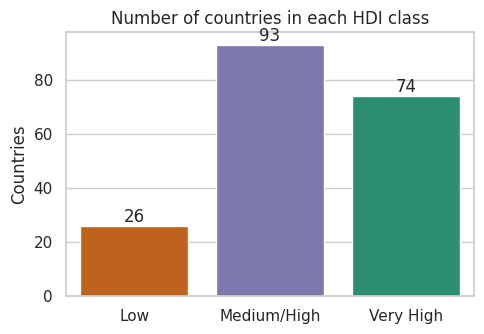

In [5]:
# number of countries per class
class_counts = df['hdi_label'].value_counts().reindex(class_order)
class_table = pd.DataFrame({
    'Count': class_counts,
    'Percentage (%)': (class_counts / len(df) * 100).round(1)
})
print(class_table)
print()
print('HDI range in each class:')
print(df.groupby('hdi_label')['hdi'].agg(['min', 'max']).reindex(class_order))

plt.figure(figsize=(5, 3.5))
ax = sns.countplot(data=df, x='hdi_label', order=class_order, hue='hdi_label', palette=class_colors, legend=False)
for bar in ax.patches:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), int(bar.get_height()), ha='center', va='bottom')
plt.title('Number of countries in each HDI class')
plt.xlabel('')
plt.ylabel('Countries')
save_fig('eda_class_counts')

In [6]:
# which features have the most missing values
missing_summary = pd.DataFrame({
    'Missing Count': df[num_cols + cat_cols].isnull().sum(),
    'Percentage (%)': df[num_cols + cat_cols].isnull().mean() * 100
}).sort_values(by='Percentage (%)', ascending=False)
print(missing_summary)

                    Missing Count  Percentage (%)
trade                          23           11.92
inflation                      15            7.77
unemployment                   14            7.25
internet_users                  8            4.15
DominantSector                  7            3.63
industry_share                  7            3.63
agriculture_share               7            3.63
gdp_growth                      4            2.07
infant_mortality                2            1.04
electricity_access              0            0.00
region                          0            0.00


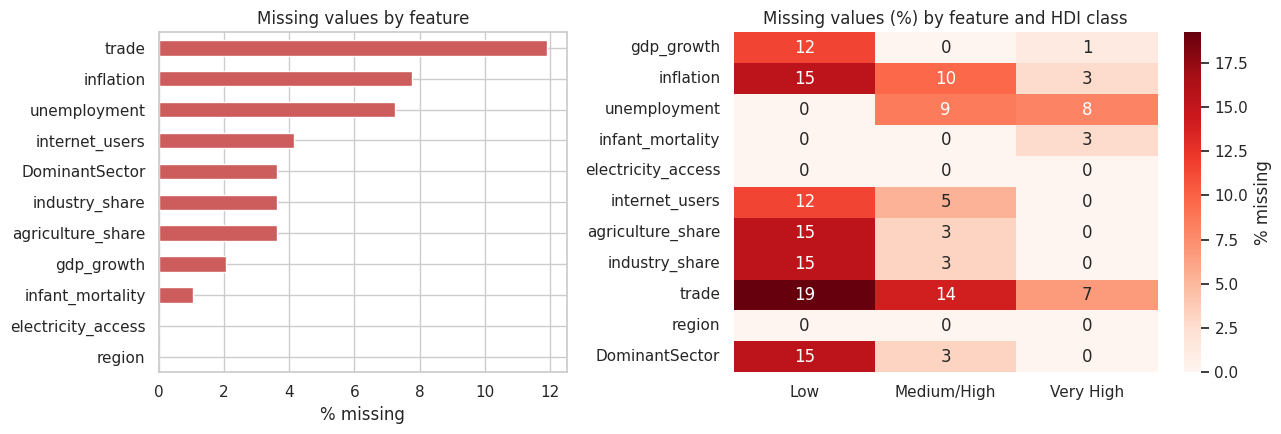

In [7]:
# same thing but split by class (in %)
miss_by_class = pd.DataFrame()
for label in class_order:
    subset = df[df['hdi_label'] == label]
    miss_by_class[label] = subset[num_cols + cat_cols].isnull().mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={'width_ratios': [1, 1.3]})

missing_summary['Percentage (%)'].plot.barh(ax=axes[0], color='indianred')
axes[0].invert_yaxis()
axes[0].set_xlabel('% missing')
axes[0].set_title('Missing values by feature')

sns.heatmap(miss_by_class, annot=True, fmt='.0f', cmap='Reds', cbar_kws={'label': '% missing'}, ax=axes[1])
axes[1].set_title('Missing values (%) by feature and HDI class')
save_fig('eda_missingness')

Low is the smallest class (26 of 193 countries), so we will use a stratified split and macro F1 instead of plain
accuracy. Not much is missing overall (trade is the worst at 11.9%), but the gaps aren't spread evenly across the
classes. We come back to that in section 6.

## 2. Distributions, skewness and outliers

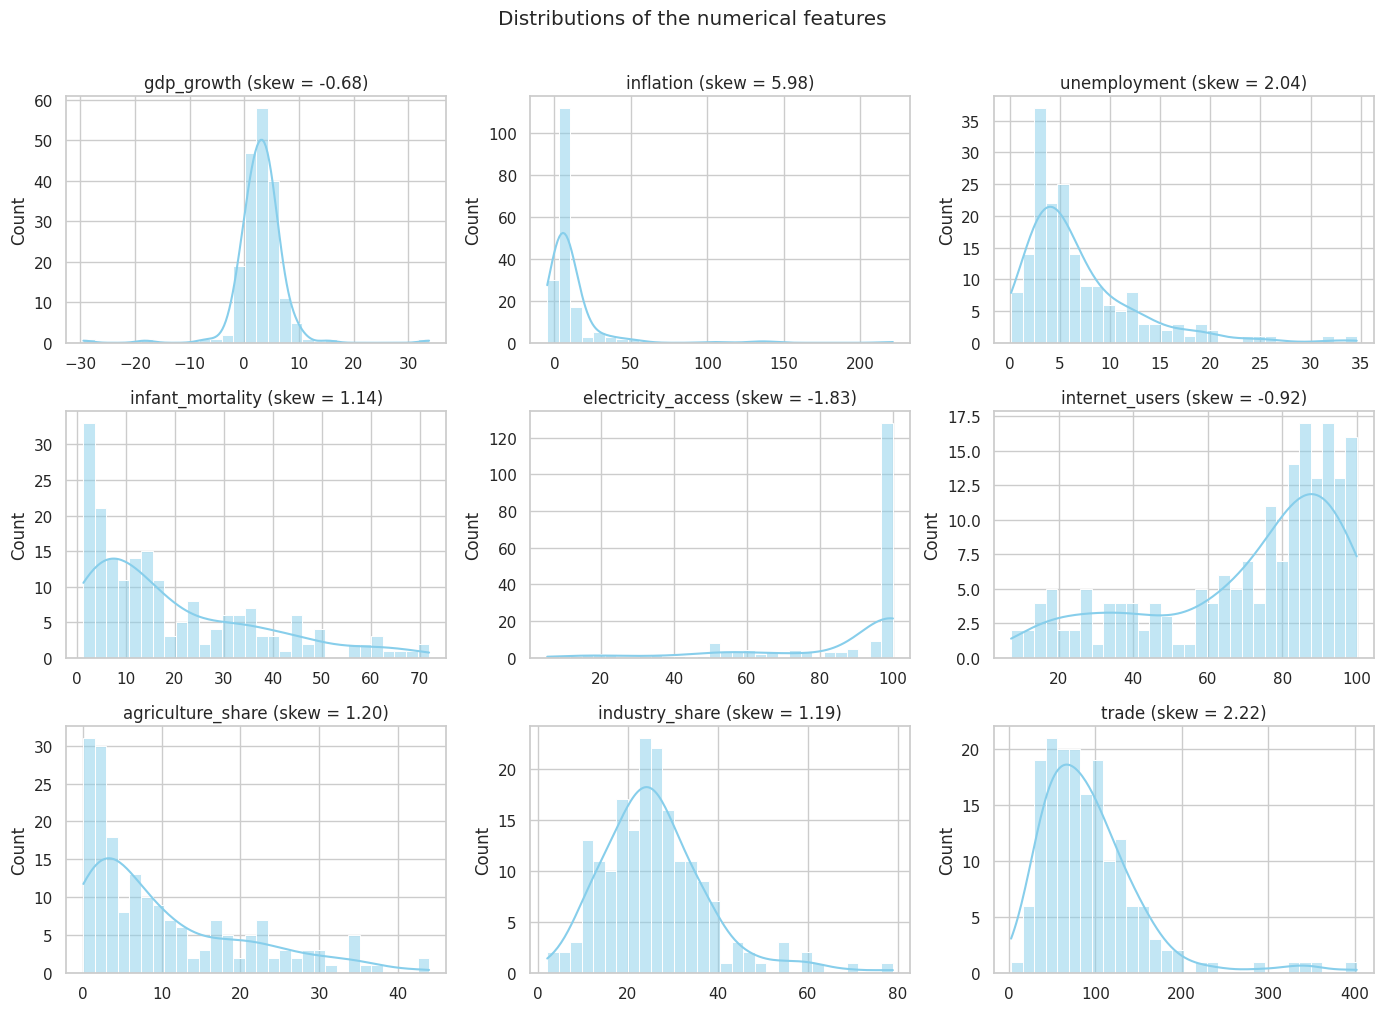

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.histplot(df[col].dropna(), kde=True, bins=30, color='skyblue', ax=axes[i])
    axes[i].set_title(f'{col} (skew = {df[col].skew():.2f})')
    axes[i].set_xlabel('')
plt.suptitle('Distributions of the numerical features', y=1.01)
save_fig('eda_histograms')

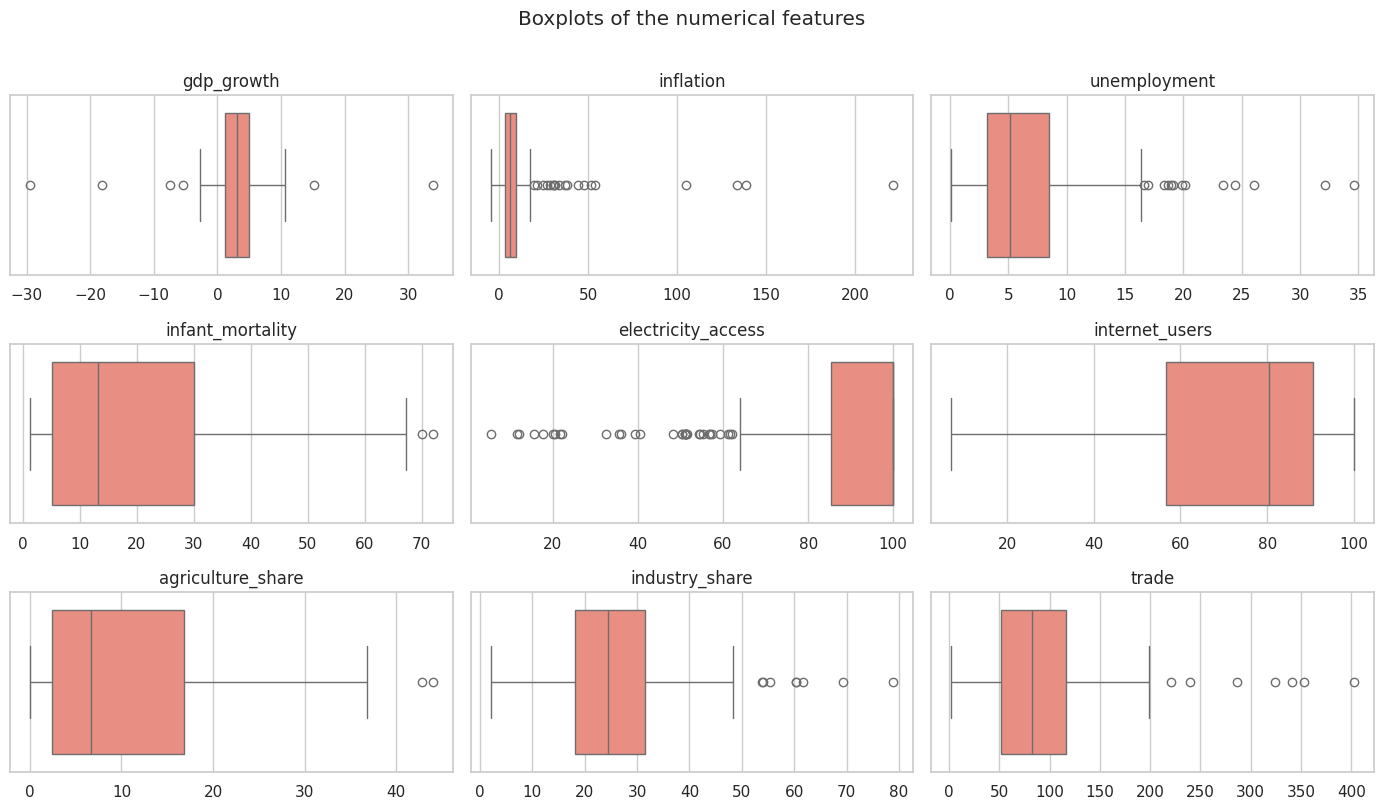

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(14, 8))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.boxplot(x=df[col], color='salmon', ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel('')
plt.suptitle('Boxplots of the numerical features', y=1.01)
save_fig('eda_boxplots')

In [10]:
# IQR rule from the lecture, anything beyond k*IQR from Q1 or Q3 is an outlier
def detect_outliers_iqr(data, col, k=1.5):
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - k * IQR
    upper = Q3 + k * IQR
    return data[(data[col] < lower) | (data[col] > upper)]

rows = []
for col in num_cols:
    mild = detect_outliers_iqr(df, col, k=1.5)
    extreme = detect_outliers_iqr(df, col, k=3.0)
    rows.append({
        'feature': col,
        'outliers (1.5 IQR)': len(mild),
        'extreme (3 IQR)': len(extreme),
        'extreme countries': ', '.join(extreme.sort_values(col)['country']),
    })

pd.set_option('display.max_colwidth', 120)
pd.DataFrame(rows).set_index('feature')

,outliers (1.5 IQR),extreme (3 IQR),extreme countries
feature,,,
gdp_growth,6,3,"Sudan, Timor-Leste, Guyana"
inflation,19,16,"Burundi, Malawi, Ethiopia, Pakistan, Lao People's Democratic Republic, Egypt, Haiti, Ghana, Iran (Islamic Republic o..."
unemployment,13,3,"Djibouti, South Africa, Eswatini (Kingdom of)"
infant_mortality,2,0,
electricity_access,33,14,"South Sudan, Burundi, Chad, Malawi, Central African Republic, Niger, Papua New Guinea, Burkina Faso, Congo (Democrat..."
internet_users,0,0,
agriculture_share,2,0,
industry_share,8,1,Libya
trade,7,4,"Singapore, San Marino, Hong Kong, China (SAR), Luxembourg"


In [11]:
# any values that can't be right?
pct_cols = ['unemployment', 'electricity_access', 'internet_users', 'agriculture_share', 'industry_share']
outside_range = ((df[pct_cols] < 0) | (df[pct_cols] > 100)).sum().sum()
print('Percentages outside 0-100:', outside_range)
print('Infant mortality <= 0 or > 1000:', ((df['infant_mortality'] <= 0) | (df['infant_mortality'] > 1000)).sum())
print('Agriculture + industry > 100:', (df['agriculture_share'] + df['industry_share'] > 100).sum())

print()
print('Trade above 200% of GDP:')
print(df.loc[df['trade'] > 200, ['country', 'trade']].sort_values('trade', ascending=False).to_string(index=False))
print()
print('Inflation above 50%:')
print(df.loc[df['inflation'] > 50, ['country', 'inflation']].sort_values('inflation', ascending=False).to_string(index=False))

Percentages outside 0-100: 0
Infant mortality <= 0 or > 1000: 0
Agriculture + industry > 100: 0

Trade above 200% of GDP:
               country  trade
            Luxembourg 402.57
Hong Kong, China (SAR) 353.19
            San Marino 340.98
             Singapore 323.70
              Djibouti 285.90
               Ireland 239.65
                 Malta 221.13

Inflation above 50%:
  country  inflation
  Lebanon     221.34
    Sudan     138.81
Argentina     133.49
 Zimbabwe     104.71
  Türkiye      53.86
 Suriname      51.59


In [12]:
# inflation and GDP growth can be negative, so a normal log won't work.
# instead take the log of |x| and put the sign back
def signed_log(x):
    return np.sign(x) * np.log1p(np.abs(x))

skew_table = pd.DataFrame({
    'skew (raw)': df[num_cols].skew(),
    'skew (signed log)': df[num_cols].apply(signed_log).skew(),
})
skew_table['highly skewed'] = skew_table['skew (raw)'].abs() > 1
skew_table

,skew (raw),skew (signed log),highly skewed
gdp_growth,-0.68,-1.55,False
inflation,5.98,0.48,True
unemployment,2.04,0.16,True
infant_mortality,1.14,-0.09,True
electricity_access,-1.83,-3.03,True
internet_users,-0.92,-1.68,False
agriculture_share,1.20,-0.06,True
industry_share,1.19,-0.90,True
trade,2.22,-0.62,True


Features to log-transform: ['inflation', 'unemployment', 'infant_mortality', 'agriculture_share', 'industry_share', 'trade']


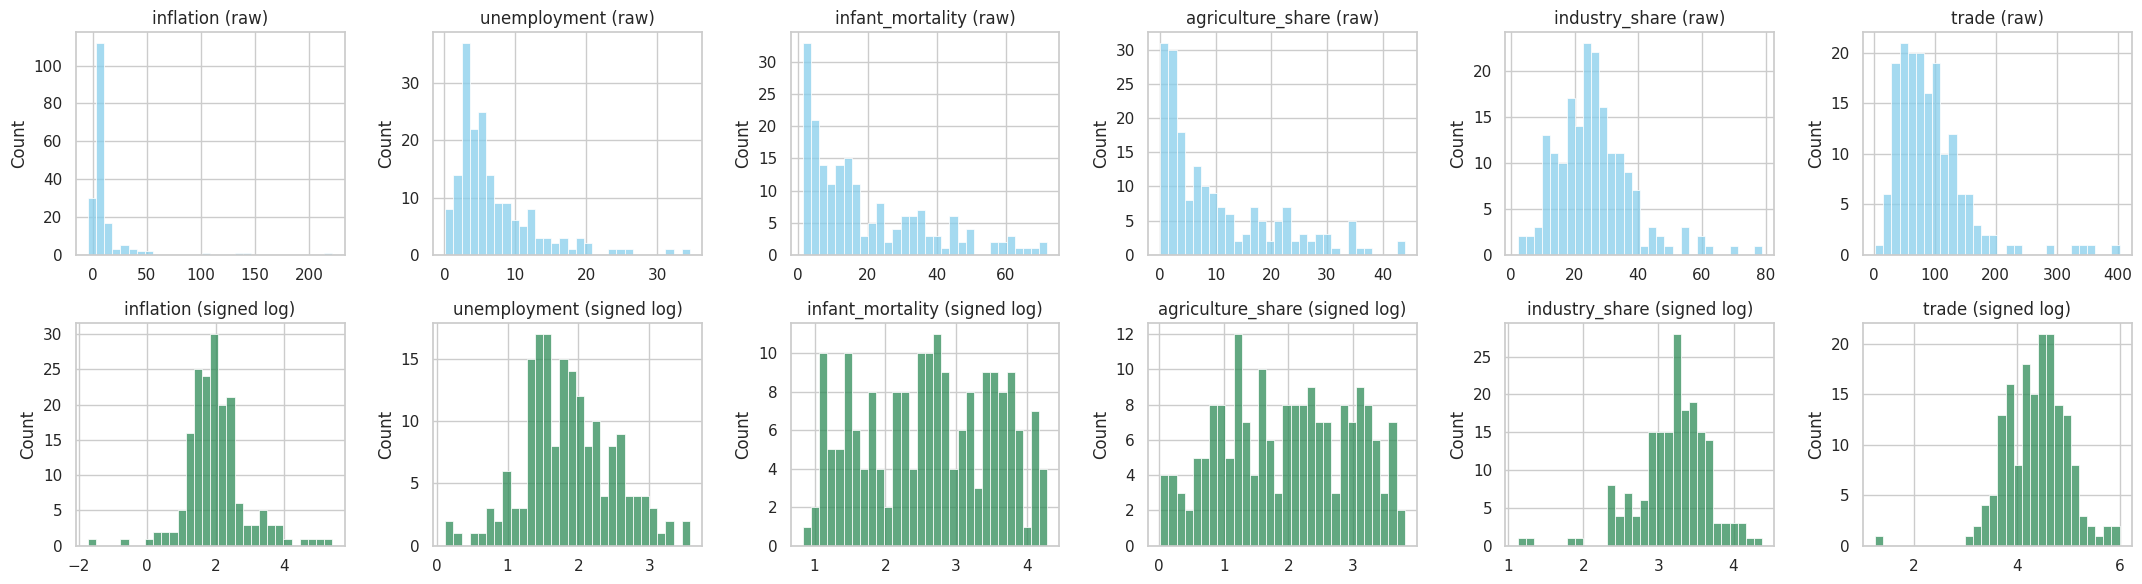

In [13]:
# only log the features that are very skewed, and only if the log actually helps
to_log = []
for col in num_cols:
    raw = abs(skew_table.loc[col, 'skew (raw)'])
    logged = abs(skew_table.loc[col, 'skew (signed log)'])
    if raw > 1 and logged < raw:
        to_log.append(col)
print('Features to log-transform:', to_log)

fig, axes = plt.subplots(2, len(to_log), figsize=(3.6 * len(to_log), 6))
for i, col in enumerate(to_log):
    sns.histplot(df[col].dropna(), bins=30, color='skyblue', ax=axes[0, i])
    axes[0, i].set_title(f'{col} (raw)')
    sns.histplot(signed_log(df[col].dropna()), bins=30, color='seagreen', ax=axes[1, i])
    axes[1, i].set_title(f'{col} (signed log)')
    axes[0, i].set_xlabel('')
    axes[1, i].set_xlabel('')
save_fig('eda_log_transform')

There are no impossible values, and the extreme ones are real (like 221% inflation in Lebanon), so we keep every country.

Six features are highly skewed and get less skewed with the signed log, so we use it on those. This mainly helps
logistic regression and PCA. Because of the skew we will also compare median and mean imputation later.

## 3. Comparing the numerical features across HDI classes

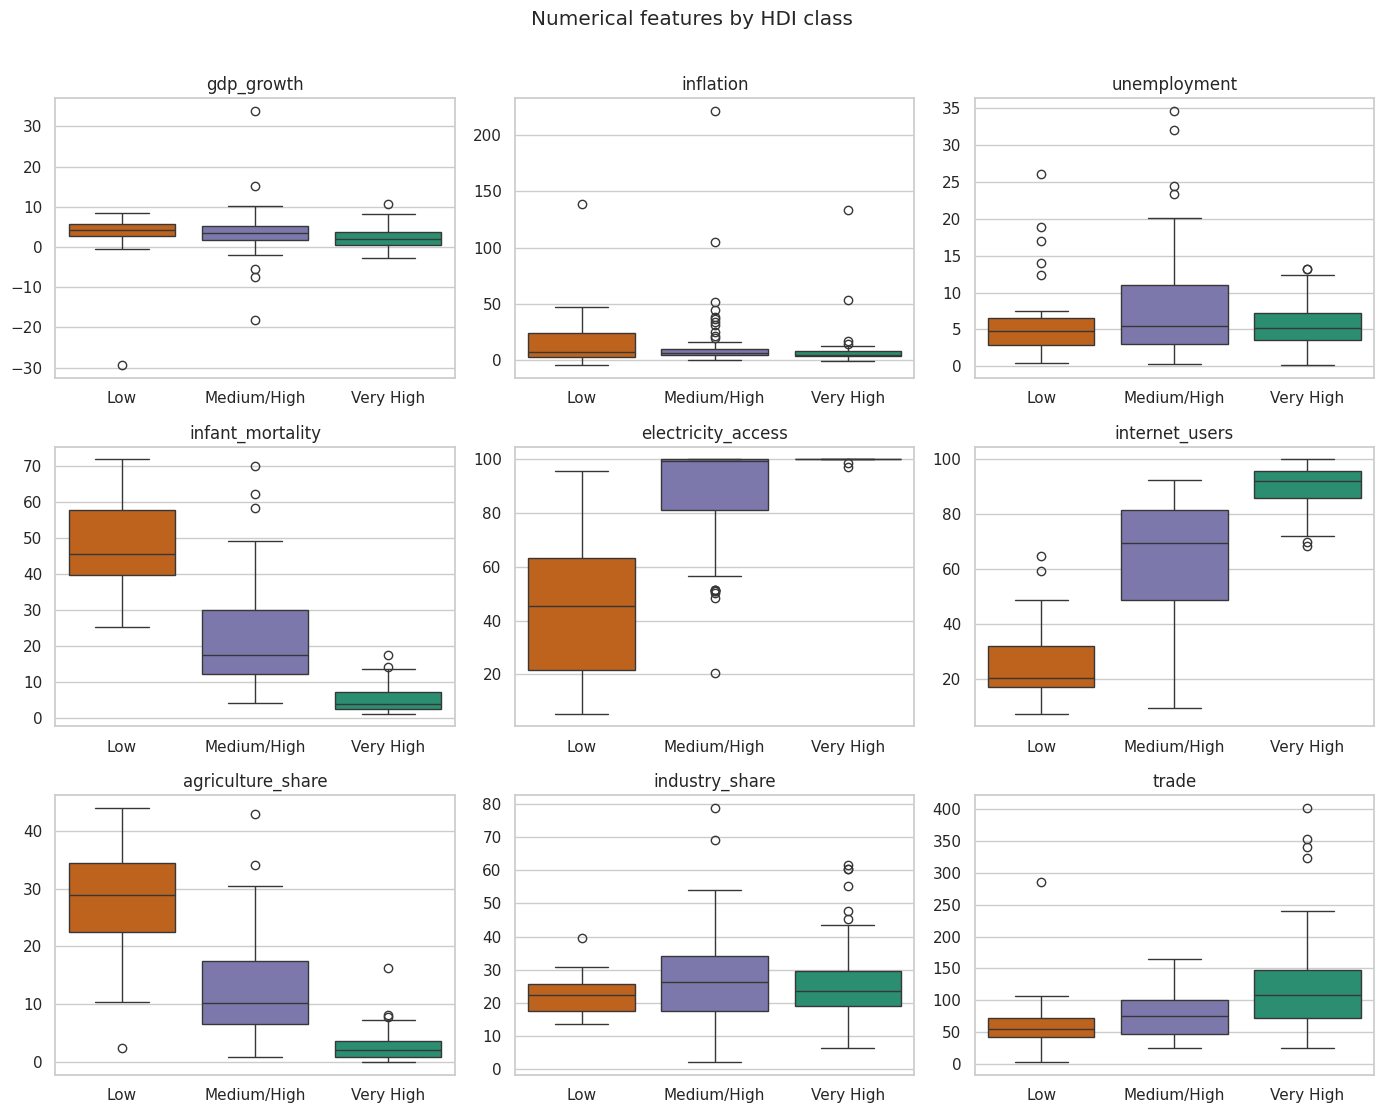

In [14]:
fig, axes = plt.subplots(3, 3, figsize=(14, 11))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.boxplot(data=df, x='hdi_label', y=col, order=class_order, hue='hdi_label',
                palette=class_colors, legend=False, ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('')
plt.suptitle('Numerical features by HDI class', y=1.01)
save_fig('eda_features_by_class')

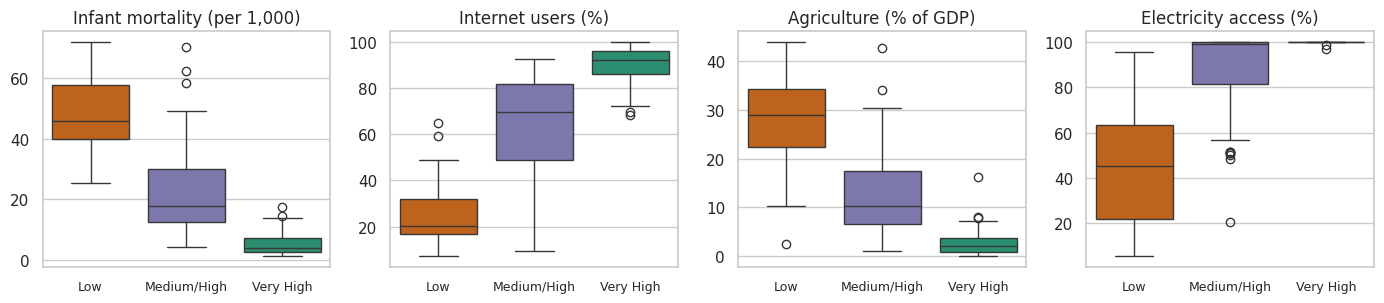

In [15]:
# only the 4 strongest features, so it fits in the report
top4 = ['infant_mortality', 'internet_users', 'agriculture_share', 'electricity_access']
titles = ['Infant mortality (per 1,000)', 'Internet users (%)', 'Agriculture (% of GDP)', 'Electricity access (%)']

fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
for i, col in enumerate(top4):
    sns.boxplot(data=df, x='hdi_label', y=col, order=class_order, hue='hdi_label',
                palette=class_colors, legend=False, ax=axes[i])
    axes[i].set_title(titles[i])
    axes[i].set_xlabel('')
    axes[i].set_ylabel('')
    axes[i].tick_params(axis='x', labelsize=9)
save_fig('report_top_features_by_class')

In [16]:
medians =df.groupby('hdi_label')[num_cols].median().T[class_order]
means = df.groupby('hdi_label')[num_cols].mean().T[class_order]
by_class = pd.concat([medians.add_suffix(' (median)'), means.add_suffix(' (mean)')], axis=1)
by_class

hdi_label,Low (median),Medium/High (median),Very High (median),Low (mean),Medium/High (mean),Very High (mean)
gdp_growth,4.26,3.52,1.95,2.85,3.55,2.19
inflation,7.47,6.03,5.03,17.74,12.86,7.96
unemployment,4.74,5.41,5.22,6.51,7.96,5.69
infant_mortality,45.70,17.70,4.00,48.33,22.26,5.14
electricity_access,45.40,99.30,100.00,44.98,88.56,99.94
internet_users,20.34,69.48,92.22,26.06,65.09,90.56
agriculture_share,28.96,10.26,2.13,27.30,12.37,2.60
industry_share,22.21,26.31,23.69,22.32,27.09,25.94
trade,55.29,74.96,107.28,66.53,77.35,122.36


In [17]:
# Kruskal-Wallis: does the feature differ between the three classes?
# most features are skewed, so we went with a non-parametric test
results = []
for col in num_cols:
    groups = [df.loc[df['hdi_label'] == label, col].dropna() for label in class_order]
    H, p = stats.kruskal(*groups)
    results.append({'feature': col, 'H': H, 'p-value': p})

pd.DataFrame(results).set_index('feature').sort_values('H', ascending=False)

,H,p-value
feature,,
infant_mortality,135.92,3.06e-30
internet_users,117.60,2.91e-26
agriculture_share,112.10,4.55e-25
electricity_access,110.99,7.91e-25
trade,29.71,3.54e-07
gdp_growth,16.17,3.07e-04
inflation,5.55,6.24e-02
industry_share,3.87,1.44e-01
unemployment,1.60,4.49e-01


Infant mortality, internet use, agriculture share and electricity access separate the classes best. Inflation,
industry share and unemployment don't differ significantly (p > 0.05). Next we check if the strong features overlap.

## 4. Correlations between the numerical features

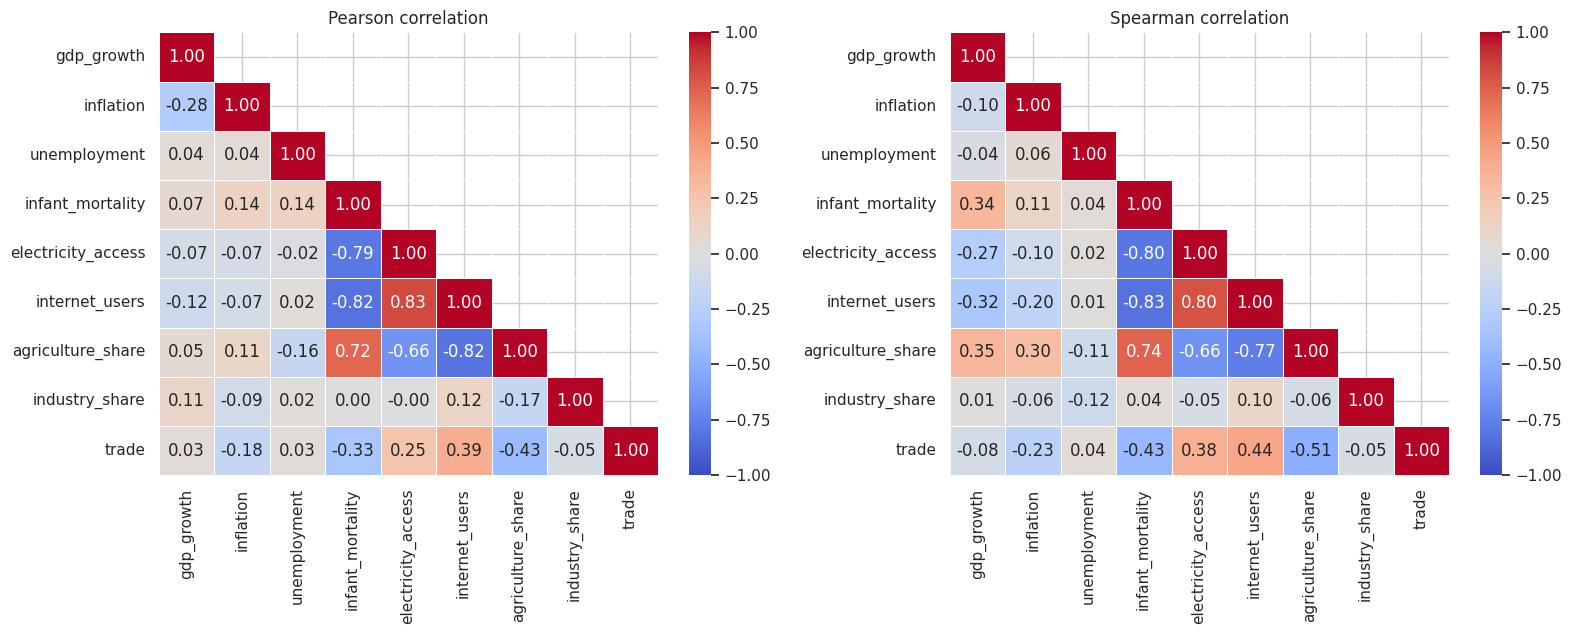

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, method in zip(axes, ['pearson', 'spearman']):
    corr = df[num_cols].corr(method=method)
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)   # hide the upper half, it's the same numbers
    sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5, ax=ax)
    ax.set_title(f'{method.title()} correlation')
save_fig('eda_correlation')

In [19]:
# top 10 most correlated pairs
spearman = df[num_cols].corr(method='spearman')
pearson = df[num_cols].corr(method='pearson')

pairs = []
for i in range(len(num_cols)):
    for j in range(i + 1, len(num_cols)):
        a, b = num_cols[i], num_cols[j]
        pairs.append({'feature 1': a, 'feature 2': b,
                      'spearman': spearman.loc[a, b], 'pearson': pearson.loc[a, b]})

pairs = pd.DataFrame(pairs)
pairs['abs_spearman'] = pairs['spearman'].abs()
pairs.sort_values('abs_spearman', ascending=False).drop(columns='abs_spearman').head(10).reset_index(drop=True)

,feature 1,feature 2,spearman,pearson
0,infant_mortality,internet_users,-0.83,-0.82
1,electricity_access,internet_users,0.80,0.83
2,infant_mortality,electricity_access,-0.80,-0.79
3,internet_users,agriculture_share,-0.77,-0.82
4,infant_mortality,agriculture_share,0.74,0.72
5,electricity_access,agriculture_share,-0.66,-0.66
6,agriculture_share,trade,-0.51,-0.43
7,internet_users,trade,0.44,0.39
8,infant_mortality,trade,-0.43,-0.33
9,electricity_access,trade,0.38,0.25


They do: the four strong features are highly correlated with each other (|ρ| from 0.66 to 0.83), so they mostly measure
the same "level of development". PCA should be able to compress them, and we need to be careful when reading the
logistic regression coefficients. Next, the two categorical features.

## 5. Categorical features: region and dominant sector

In [20]:
for col in cat_cols:
    counts = df[col].value_counts(dropna=False)
    table = pd.DataFrame({'Count': counts, 'Percentage (%)': (counts / len(df) * 100).round(1)})
    print(table)
    print()

                                                   Count  Percentage (%)
region                                                                  
Europe & Central Asia                                 51            26.4
Sub-Saharan Africa                                    48            24.9
Latin America & Caribbean                             33            17.1
East Asia & Pacific                                   30            15.5
Middle East, North Africa, Afghanistan & Pakistan     23            11.9
South Asia                                             6             3.1
North America                                          2             1.0

                Count  Percentage (%)
DominantSector                       
Services          176            91.2
Industry            8             4.1
NaN                 7             3.6
Agriculture         2             1.0



In [21]:
for col in cat_cols:
    print(f'--- {col} vs HDI class ---')
    print(pd.crosstab(df[col].fillna('Missing'), df['hdi_label'], margins=True))
    print()

--- region vs HDI class ---
hdi_label                                          Low  Medium/High  \
region                                                                
East Asia & Pacific                                  0           22   
Europe & Central Asia                                0            7   
Latin America & Caribbean                            0           23   
Middle East, North Africa, Afghanistan & Pakistan    4           11   
North America                                        0            0   
South Asia                                           0            6   
Sub-Saharan Africa                                  22           24   
All                                                 26           93   

hdi_label                                          Very High  All  
region                                                             
East Asia & Pacific                                        8   30  
Europe & Central Asia                                    

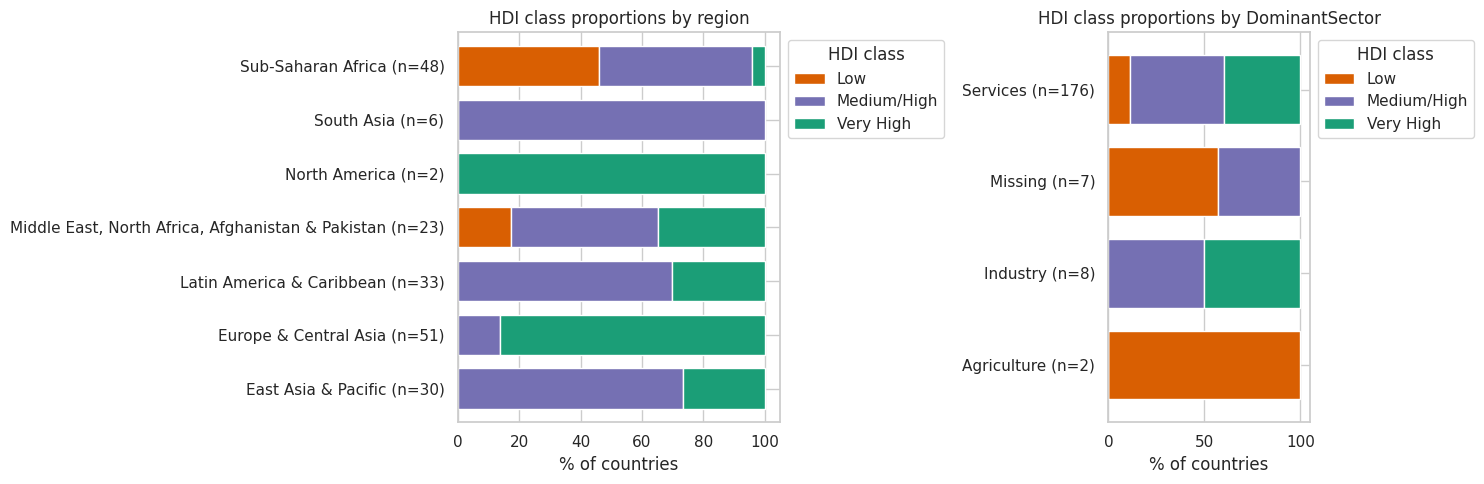

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [1.6, 1]})
for ax, col in zip(axes, cat_cols):
    values = df[col].fillna('Missing')
    ct = pd.crosstab(values, df['hdi_label'], normalize='index') * 100
    ct.plot(kind='barh', stacked=True, color=[class_colors[c] for c in class_order], ax=ax, width=0.75)

    counts = values.value_counts()
    ax.set_yticks(range(len(ct)), [f'{name} (n={counts[name]})' for name in ct.index])
    ax.set_xlabel('% of countries')
    ax.set_ylabel('')
    ax.set_title(f'HDI class proportions by {col}')
    ax.legend(title='HDI class', bbox_to_anchor=(1, 1), loc='upper left')
save_fig('eda_categorical_by_class')

Region is strongly linked to the class (22 of the 26 Low countries are in Sub-Saharan Africa). Some regions are tiny,
so the one-hot encoder will need `handle_unknown='ignore'`. DominantSector is "Services" for 91% of countries, so we
don't expect much from it.

## 6. Is missing data related to the HDI class?

In [23]:
df['n_missing'] = df[num_cols + cat_cols].isnull().sum(axis=1)
df['any_missing'] = df['n_missing'] > 0

print(pd.crosstab(df['hdi_label'], df['any_missing'], margins=True))
print()
print('% of countries with at least one missing value:')
print((df.groupby('hdi_label')['any_missing'].mean() * 100).round(1))
print()
print('Average number of missing values per country:')
print(df.groupby('hdi_label')['n_missing'].mean().round(2))

any_missing  False  True  All
hdi_label                    
Low             18     8   26
Medium/High     68    25   93
Very High       65     9   74
All            151    42  193

% of countries with at least one missing value:
hdi_label
Low            30.8
Medium/High    26.9
Very High      12.2
Name: any_missing, dtype: float64

Average number of missing values per country:
hdi_label
Low            1.04
Medium/High    0.47
Very High      0.22
Name: n_missing, dtype: float64


In [24]:
# chi-square test: does having missing data depend on the class?
table = pd.crosstab(df['hdi_label'], df['any_missing'])
chi2, p, dof, expected = stats.chi2_contingency(table)
print(f'chi2 = {chi2:.2f}, dof = {dof}, p = {p:.4f}')
print('Smallest expected count:', expected.min().round(1), '(the test is only approximate if this is below 5)')

chi2 = 6.68, dof = 2, p = 0.0355
Smallest expected count: 5.7 (the test is only approximate if this is below 5)


In [25]:
print('Countries with 3 or more missing values:')
many_missing = df.loc[df['n_missing'] >= 3, ['country', 'hdi_label', 'region', 'n_missing']]
print(many_missing.sort_values('n_missing', ascending=False).to_string(index=False))

Countries with 3 or more missing values:
                           country   hdi_label                                            region  n_missing
                             Yemen         Low Middle East, North Africa, Afghanistan & Pakistan          7
                            Tuvalu Medium/High                               East Asia & Pacific          7
                           Eritrea         Low                                Sub-Saharan Africa          6
                       South Sudan         Low                                Sub-Saharan Africa          6
                     Liechtenstein   Very High                             Europe & Central Asia          5
                             Nauru Medium/High                               East Asia & Pacific          5
                           Somalia         Low                                Sub-Saharan Africa          4
Venezuela (Bolivarian Republic of) Medium/High                         Latin America & Caribbea

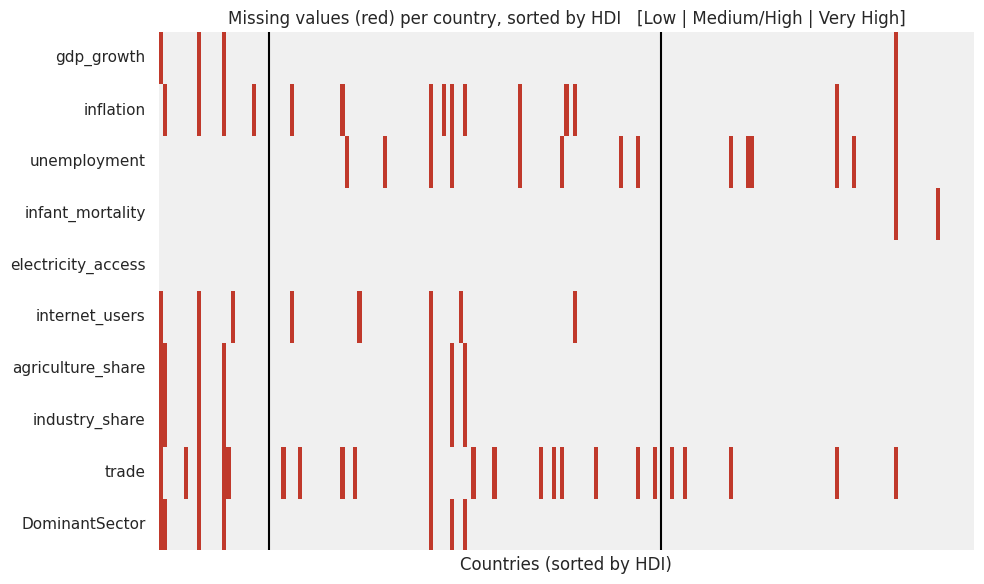

In [26]:
# each column is a country (lowest HDI on the left), black lines are where the class changes
sorted_df = df.sort_values(['hdi_class', 'hdi'])

plt.figure(figsize=(10, 6))
sns.heatmap(sorted_df[num_cols + ['DominantSector']].isna().T, cbar=False,
            cmap=['#f0f0f0', '#c0392b'], xticklabels=False)
class_change = np.where(np.diff(sorted_df['hdi_class'].values) != 0)[0] + 1
for x in class_change:
    plt.axvline(x, color='black', lw=1.5)
plt.title('Missing values (red) per country, sorted by HDI   [Low | Medium/High | Very High]')
plt.xlabel('Countries (sorted by HDI)')
save_fig('eda_missing_pattern')

Missing data is not random: 31% of Low and 27% of Medium/High countries have a gap, compared to 12% of Very High
(p = 0.036). So we will try missingness indicators, keeping in mind that they tell us about data availability and not
about development itself.

## Summary: what we take into modeling

| What we found | What we do |
|---|---|
| Low is only 13.5% of countries | Stratified split and CV, macro F1 |
| Skewed features, extreme values are real | Keep all countries, signed log on 6 features, median vs mean imputation |
| Missing data depends on the class | Try missingness indicators |
| Four features are strongly correlated | Try PCA, be careful with the coefficients |
| Very small regions | `handle_unknown='ignore'` in the one-hot encoder |
| DominantSector is 91% Services | Keep it for the feature-set comparison |